<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/gato_batched_trajectory_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# [CELL 1 - Environment Setup & Imports]
import torch
import torch.nn as nn
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"GATO Batched Trajectory Optimization Benchmark initialized on: {device}")
if torch.cuda.is_available():
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")

GATO Batched Trajectory Optimization Benchmark initialized on: cuda
GPU Device Name: Tesla T4


In [6]:
# [CELL 2 - Batched Inverted Pendulum / Manipulator Dynamics & Costs]

class BatchedPendulumDynamics(nn.Module):
    """
    Batched non-linear continuous dynamics x_dot = f(x, u) discretized via Euler step.
    State x = [theta, dtheta], Control u = [torque]
    """
    def __init__(self, dt: float = 0.05, g: float = 9.81, m: float = 1.0, l: float = 1.0):
        super().__init__()
        self.dt = dt
        self.g = g
        self.m = m
        self.l = l

        # State and Control dimensions
        self.dx = 2
        self.du = 1

    def forward(self, x: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
        """
        x: (Batch_Size, 2)
        u: (Batch_Size, 1)
        """
        theta, dtheta = x[:, 0:1], x[:, 1:2]
        d2theta = (self.g / self.l) * torch.sin(theta) + u / (self.m * self.l**2)

        theta_next = theta + dtheta * self.dt
        dtheta_next = dtheta + d2theta * self.dt
        return torch.cat([theta_next, dtheta_next], dim=-1)

class BatchedQuadraticCost:
    """Computes quadratic tracking loss across a batch of trajectories."""
    def __init__(self, Q: torch.Tensor, R: torch.Tensor, Qf: torch.Tensor, x_goal: torch.Tensor):
        self.Q = Q    # (dx, dx)
        self.R = R    # (du, du)
        self.Qf = Qf  # (dx, dx)
        self.x_goal = x_goal # (1, dx)

    def stage_cost(self, x: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
        """x: (B, dx), u: (B, du) -> (B,)"""
        err = x - self.x_goal
        cost_x = torch.sum((err @ self.Q) * err, dim=-1)
        cost_u = torch.sum((u @ self.R) * u, dim=-1)
        return 0.5 * (cost_x + cost_u)

    def terminal_cost(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, dx) -> (B,)"""
        err = x - self.x_goal
        return 0.5 * torch.sum((err @ self.Qf) * err, dim=-1)

print("Batched Dynamics and Quadratic Cost Models Instantiated.")

Batched Dynamics and Quadratic Cost Models Instantiated.


In [16]:
# [CELL 3 - GPU-Accelerated Batched Gradient Trajectory Optimizer]

class BatchedGradientTrajectoryOptimizer:
    """
    Differentiable Batched Trajectory Optimizer executing parallel forward rollouts,
    autograd backpropagation, and batched gradient descent updates across batch dimension B.
    """
    def __init__(self, dynamics: BatchedPendulumDynamics, cost: BatchedQuadraticCost, T: int = 20):
        self.dyn = dynamics
        self.cost = cost
        self.T = T
        self.dx = dynamics.dx
        self.du = dynamics.du

    def solve(self, x0_batch: torch.Tensor, num_iters: int = 5) -> Tuple[torch.Tensor, torch.Tensor]:
        B = x0_batch.shape[0]
        dev = x0_batch.device

        # Initialize control sequence as leaf tensor tracking gradients
        U = torch.zeros(B, self.T, self.du, device=dev, requires_grad=True)

        for itr in range(num_iters):
            # 1. Parallel Forward Rollout
            X_list = [x0_batch]
            for t in range(self.T):
                x_next = self.dyn(X_list[-1], U[:, t])
                X_list.append(x_next)

            X = torch.stack(X_list, dim=1) # (B, T+1, dx)

            # 2. Parallel Cost Evaluation (SUM across batch to prevent 1/B gradient dilution)
            total_cost = torch.sum(self.cost.terminal_cost(X[:, -1]))
            for t in range(self.T):
                total_cost = total_cost + torch.sum(self.cost.stage_cost(X[:, t], U[:, t]))

            # 3. Backward Pass
            total_cost.backward()

            # 4. Control Update
            with torch.no_grad():
                if U.grad is not None:
                    U_updated = U - 0.01 * U.grad
                else:
                    U_updated = U

            # Detach and re-enable gradients cleanly for next iteration
            U = U_updated.detach().requires_grad_(True)

        # Final rollout with optimized controls
        with torch.no_grad():
            X_list = [x0_batch]
            for t in range(self.T):
                X_list.append(self.dyn(X_list[-1], U[:, t]))
            X = torch.stack(X_list, dim=1)

        return X, U

print("Optimizer renamed to BatchedGradientTrajectoryOptimizer and 1/B gradient scaling fixed.")

Optimizer renamed to BatchedGradientTrajectoryOptimizer and 1/B gradient scaling fixed.


In [19]:
# [CELL 4 - Multi-Trial Execution Benchmark Across Batch Sizes]

dx, du = 2, 1
Q = torch.eye(dx, device=device)
R = 0.1 * torch.eye(du, device=device)
Qf = 10.0 * torch.eye(dx, device=device)
x_goal = torch.tensor([[np.pi, 0.0]], device=device)

dyn = BatchedPendulumDynamics().to(device)
cost_fn = BatchedQuadraticCost(Q, R, Qf, x_goal)
solver = BatchedGradientTrajectoryOptimizer(dyn, cost_fn, T=25)

batch_sizes = [1, 16, 64, 256, 512]
execution_latencies_ms = []
throughput_solves_per_sec = []

# Warmup run (3 iterations)
dummy_x0 = torch.randn(1, dx, device=device)
for _ in range(3):
    _ = solver.solve(dummy_x0, num_iters=2)
if torch.cuda.is_available():
    torch.cuda.synchronize()

print("Beginning Multi-Trial Benchmark Runs...")

for B in batch_sizes:
    trial_times = []
    x0_batch = torch.randn(B, dx, device=device)

    # Run 3 trials per batch size
    for trial in range(3):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t_start = time.perf_counter()

        _ = solver.solve(x0_batch, num_iters=5)

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t_end = time.perf_counter()
        trial_times.append((t_end - t_start) * 1000.0)

    median_time_ms = float(np.median(trial_times))
    solves_per_sec = (B / (median_time_ms / 1000.0))

    execution_latencies_ms.append(median_time_ms)
    throughput_solves_per_sec.append(solves_per_sec)

    print(f"Batch Size {B:3d} | Median Latency: {median_time_ms:6.2f} ms | Throughput: {solves_per_sec:8.1f} solves/sec")

print("Benchmark Execution Finished.")

Beginning Multi-Trial Benchmark Runs...
Batch Size   1 | Median Latency: 122.06 ms | Throughput:      8.2 solves/sec
Batch Size  16 | Median Latency: 134.18 ms | Throughput:    119.2 solves/sec
Batch Size  64 | Median Latency: 141.23 ms | Throughput:    453.2 solves/sec
Batch Size 256 | Median Latency: 133.78 ms | Throughput:   1913.6 solves/sec
Batch Size 512 | Median Latency: 142.82 ms | Throughput:   3585.0 solves/sec
Benchmark Execution Finished.


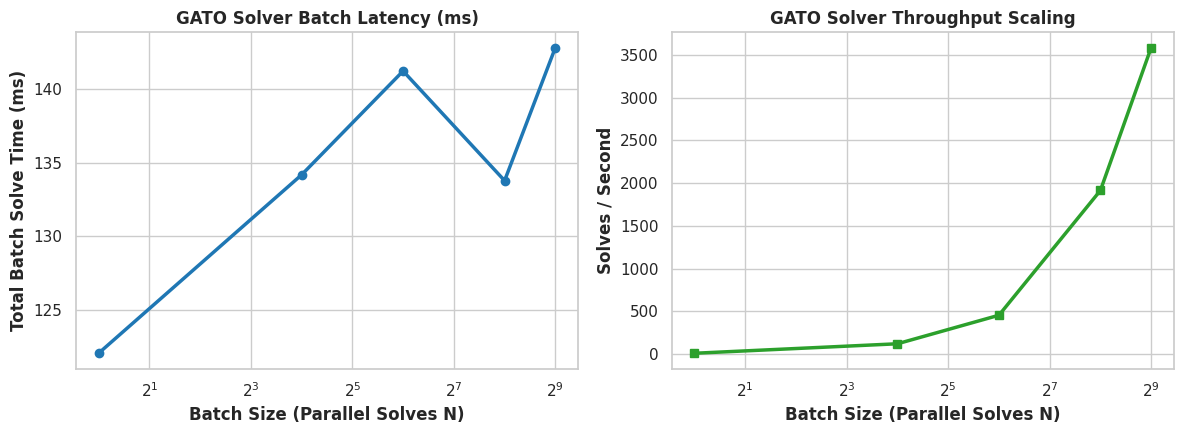

GATO benchmark plot saved successfully as gato_batched_mpc_benchmark.png.


In [20]:
# [CELL 5 - Benchmark Visualization Plotting]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel A: Latency vs Batch Size
axes[0].plot(batch_sizes, execution_latencies_ms, marker='o', color='#1f77b4', lw=2.5)
axes[0].set_title("GATO Solver Batch Latency (ms)", fontweight='bold')
axes[0].set_xlabel("Batch Size (Parallel Solves N)", fontweight='bold')
axes[0].set_ylabel("Total Batch Solve Time (ms)", fontweight='bold')
axes[0].set_xscale('log', base=2)

# Panel B: Solves per Second Throughput
axes[1].plot(batch_sizes, throughput_solves_per_sec, marker='s', color='#2ca02c', lw=2.5)
axes[1].set_title("GATO Solver Throughput Scaling", fontweight='bold')
axes[1].set_xlabel("Batch Size (Parallel Solves N)", fontweight='bold')
axes[1].set_ylabel("Solves / Second", fontweight='bold')
axes[1].set_xscale('log', base=2)

plt.tight_layout()
plt.savefig("gato_batched_mpc_benchmark.png", dpi=300)
plt.show()

print("GATO benchmark plot saved successfully as gato_batched_mpc_benchmark.png.")